# 03 – Yearly range

Measure how the range of the ring-necked parakeet in the UK has grown over time.

**Metric:** the area occupied each year, from the number of occupied 10 km squares (each 100 km²). Following Skellam (1951), √(occupied area) is plotted against year: for a population spreading outwards from a centre, this gives a straight line whose slope is the spread rate (km per year). Changes in slope show the spread speeding up or slowing down.

**Comparison:** the same metric with 2 km squares, from the early 1990s onwards, when 10 km records are rare (see `02_spatial-unit` and `decisions.md`, "Spatial unit").

**Caveat:** an occupied square means at least one record, not a confirmed population. The growth in recording (e.g. eBird, BirdTrack) also increases the occupied area, so part of the trend may reflect recording effort rather than spread. This is handled in a later step.

Input: `data/processed/records.parquet`, built by `src/build_records.py` (merged and filtered GBIF + NBN records, with 10 km and 2 km square IDs).

In [ ]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from IPython.display import Image
from matplotlib.animation import FuncAnimation, PillowWriter
from matplotlib.patches import Patch
from shapely.geometry import box

RECORDS_PATH = "../data/processed/records.parquet"
FIGURES = Path("../figures")

## Load data

In [ ]:
records = pd.read_parquet(RECORDS_PATH)

print(f"{len(records):,} records")  # expected: 433,993 (see decisions.md)
print(f"Years: {records['year'].min()}–{records['year'].max()}")
print(f"Occupied squares: {records['hectad'].nunique():,} (10 km), {records['tetrad'].nunique():,} (2 km)")
records["source"].value_counts()

In [ ]:
# Columns used in this notebook
records[["source", "year", "hectad", "tetrad", "coordinateUncertaintyInMeters"]].head()

## Animation: occupied 10 km squares per year

One frame per year. Dark blue: squares with at least one record in that year. Light blue: squares with records in earlier years but not in this one. Together they show how the recorded range builds up. The last year stays on screen for a few seconds at the end.

Saved to `figures/`:
- `hectads_by_year.mp4` for slides (can be paused in PowerPoint)
- `hectads_by_year.gif` for the notebook and README

Years without records (several in the 1960s) show only the earlier squares. Keep in mind that the yearly pattern also reflects recording effort: in recent years, many more squares have records simply because many more people record.

In [13]:
# Which 10 km squares have records in which year (one row per square and year)
year_squares = records[["year", "hectad"]].drop_duplicates()
first_year = year_squares.groupby("hectad")["year"].min()  # first year each square has a record

# One polygon per square, in km (square ID = south-west corner in km, e.g. "530_180")
corner = first_year.index.str.split("_", expand=True).to_frame().astype(int)
squares = gpd.GeoSeries(
    [box(e, n, e + 10, n + 10) for e, n in zip(corner[0], corner[1])],
    index=first_year.index,
)

# Land outline: Natural Earth (public domain), same file as in 02_spatial-unit
LAND_URL = "https://naciscdn.org/naturalearth/10m/cultural/ne_10m_admin_0_countries.zip"
LAND_PATH = Path("../data/external/ne_10m_admin_0_countries.zip")
if not LAND_PATH.exists():
    LAND_PATH.parent.mkdir(parents=True, exist_ok=True)
    LAND_PATH.write_bytes(requests.get(LAND_URL, timeout=60).content)

countries = gpd.read_file(LAND_PATH)
land = (
    countries[countries["ADM0_A3"].isin(["GBR", "IRL", "IMN"])]
    .to_crs("EPSG:27700")
    .geometry.scale(xfact=0.001, yfact=0.001, origin=(0, 0))  # metres -> km
)

# Map extent: the whole of Great Britain and Ireland plus a margin, the same in every frame
xmin, ymin, xmax, ymax = land.total_bounds #+ np.array([-20, -20, 20, 20])

print(f"{len(squares):,} squares, {year_squares['year'].nunique()} years with records")
print(f"Map extent: {xmin:.0f} to {xmax:.0f} km east, {ymin:.0f} to {ymax:.0f} km north")

1,102 squares, 62 years with records
Map extent: -297 to 656 km east, 10 to 1219 km north


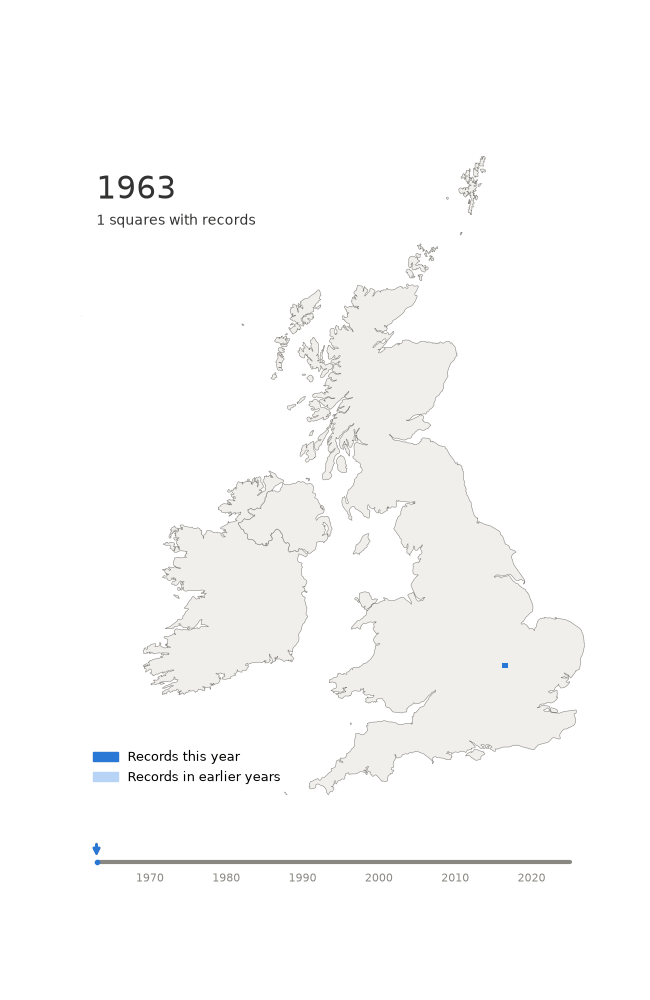

In [18]:
# Colours: one blue for "this year", a light step of the same blue for "earlier years"
THIS_YEAR = "#2a78d6"
EARLIER = "#b7d3f6"
LAND = "#f0efec"
LAND_EDGE = "#898781"
TEXT = "#333333"
MUTED = "#898781"

FPS = 4           # years per second
HOLD_SECONDS = 2  # how long the last year stays on screen at the end
LAST_YEAR = 2025  # 2026 is incomplete (downloaded in November)

years = list(range(int(records["year"].min()), LAST_YEAR + 1))
frames = years + [years[-1]] * (FPS * HOLD_SECONDS)  # repeat the last year to hold it

# Map on top, timeline underneath
fig = plt.figure(figsize=(6.5, 10))
grid = fig.add_gridspec(2, 1, height_ratios=[14, 1], hspace=0.02)
ax = fig.add_subplot(grid[0])
tl = fig.add_subplot(grid[1])


def draw_map(year):
    """Squares with records in `year`, and squares recorded only in earlier years."""
    ax.clear()
    land.plot(ax=ax, color=LAND, edgecolor=LAND_EDGE, linewidth=0.4)

    this_year = set(year_squares.loc[year_squares["year"] == year, "hectad"])
    earlier = set(first_year.index[first_year < year]) - this_year

    if earlier:
        squares.loc[list(earlier)].plot(ax=ax, color=EARLIER, linewidth=0)
    if this_year:
        squares.loc[list(this_year)].plot(ax=ax, color=THIS_YEAR, linewidth=0)

    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    ax.set_aspect("equal")
    ax.set_axis_off()
    ax.text(0.03, 0.97, str(year), transform=ax.transAxes, fontsize=22, va="top", color=TEXT)
    ax.text(0.03, 0.91, f"{len(this_year)} squares with records", transform=ax.transAxes,
            fontsize=10, va="top", color=TEXT)
    ax.legend(
        handles=[Patch(color=THIS_YEAR, label="Records this year"),
                 Patch(color=EARLIER, label="Records in earlier years")],
        loc="lower left", frameon=False, fontsize=9,
    )


def draw_timeline(year):
    """A line from the first to the last year, filled up to `year`, with an arrow at `year`."""
    tl.clear()
    tl.plot([years[0], years[-1]], [0, 0], color=MUTED, linewidth=3, solid_capstyle="round")
    tl.plot([years[0], year], [0, 0], color=EARLIER, linewidth=3, solid_capstyle="round")
    tl.plot([year],[0], color=THIS_YEAR, marker='.')
    tl.annotate("", xy=(year, 0.15), xytext=(year, 1.0),
                arrowprops=dict(arrowstyle="-|>", color=THIS_YEAR, linewidth=2))

    # Decade labels under the line
    for decade in range((years[0] // 10 + 1) * 10, years[-1] + 1, 10):
        tl.text(decade, -0.5, str(decade), ha="center", va="top", fontsize=8, color=MUTED)

    tl.set_xlim(years[0] - 2, years[-1] + 2)
    tl.set_ylim(-1.3, 1.1)
    tl.set_axis_off()


def draw(year):
    draw_map(year)
    draw_timeline(year)


anim = FuncAnimation(fig, draw, frames=frames)
FIGURES.mkdir(exist_ok=True)

# MP4 for slides (play/pause in PowerPoint, sharp at dpi=200); needs ffmpeg
anim.save(FIGURES / "hectads_by_year.mp4", writer="ffmpeg", fps=FPS, dpi=200)
# GIF for the notebook and README (plays anywhere, loops)
anim.save(FIGURES / "hectads_by_year.gif", writer=PillowWriter(fps=FPS))
plt.close(fig)  # don't also show the last frame as a static plot

Image(filename=FIGURES / "hectads_by_year.gif")

## Occupied area per year (10 km squares)

Two ways to count occupied squares in a year:

- **Yearly:** squares with at least one record in that year. Closest to "where the birds are now", but sensitive to recording effort, and it can drop in a year with few records.
- **Cumulative:** squares with a record in that year or any earlier year. It never drops, but it keeps squares where a single bird (e.g. an escape) was seen long ago, so it can overstate the range.

The true range is somewhere in between. Area = number of squares × 100 km². Following Skellam (1951), √(area) is plotted against year: a straight line means a constant spread rate, and its slope is the rate in km per year.

In [19]:
# Number of occupied 10 km squares per year (`years` runs to LAST_YEAR, set in the animation cell)
yearly = year_squares.groupby("year")["hectad"].nunique()
cumulative = first_year.value_counts().sort_index().cumsum()  # squares first recorded up to each year

range_10km = pd.DataFrame({
    "squares_yearly": yearly.reindex(years, fill_value=0),
    "squares_cumulative": cumulative.reindex(years).ffill().fillna(0).astype(int),
})
range_10km.index.name = "year"

# Area in km² (each square is 10 × 10 km) and its square root (km)
for kind in ["yearly", "cumulative"]:
    range_10km[f"area_{kind}"] = range_10km[f"squares_{kind}"] * 100
    range_10km[f"sqrt_area_{kind}"] = np.sqrt(range_10km[f"area_{kind}"])

range_10km.round(1)

,squares_yearly,squares_cumulative,area_yearly,sqrt_area_yearly,area_cumulative,sqrt_area_cumulative
year,,,,,,
1963,1,1,100,10.0,100,10.0
1964,1,2,100,10.0,200,14.1
1965,0,2,0,0.0,200,14.1
1966,0,2,0,0.0,200,14.1
1967,2,4,200,14.1,400,20.0
...,...,...,...,...,...,...
2021,401,946,40100,200.2,94600,307.6
2022,392,978,39200,198.0,97800,312.7
2023,438,1014,43800,209.3,101400,318.4


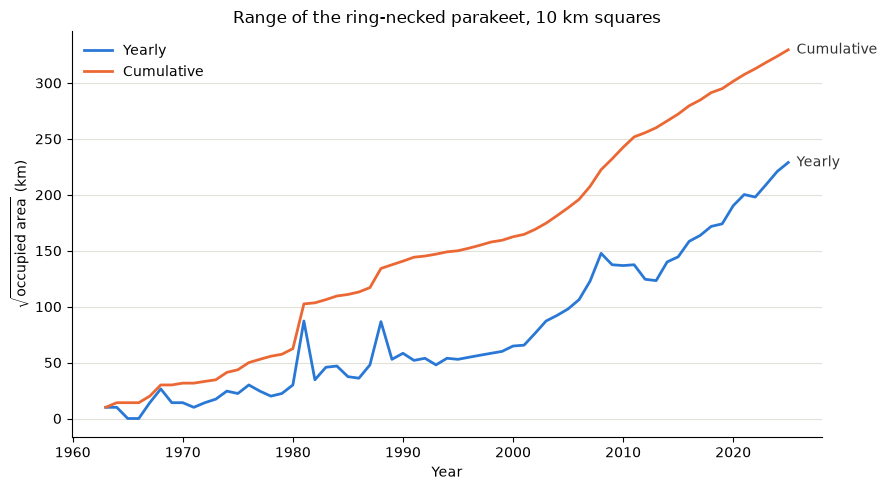

In [22]:
# Plot √(area) against year for both measures
YEARLY_COLOUR = "#2a78d6"      # blue, same as "records this year" in the animation
CUMULATIVE_COLOUR = "#eb6834"  # orange
GRID = "#e1e0d9"

fig, ax = plt.subplots(figsize=(9, 5))
for col, colour, label in [("sqrt_area_yearly", YEARLY_COLOUR, "Yearly"),
                           ("sqrt_area_cumulative", CUMULATIVE_COLOUR, "Cumulative")]:
    ax.plot(range_10km.index, range_10km[col], color=colour, linewidth=2, label=label)
    # label each line at its right-hand end
    ax.annotate(label, (range_10km.index[-1], range_10km[col].iloc[-1]),
                xytext=(6, 0), textcoords="offset points", va="center", color=TEXT)

ax.set_xlabel("Year")
ax.set_ylabel(r"$\sqrt{\text{occupied area}}$ (km)")
ax.set_title("Range of the ring-necked parakeet, 10 km squares")
ax.legend(frameon=False, loc="upper left")
ax.grid(axis="y", color=GRID, linewidth=0.8)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()

fig.savefig(FIGURES / "sqrt_area_10km.png", dpi=200)

## Comparison: 2 km squares (from 1992)

The same yearly measure with 2 km squares, from 1992, when 10 km-only records have become rare. The 2 km area is always smaller: a 10 km square counts as fully occupied even if the birds use only part of it. So compare how the two lines change, not their height:

- If the ratio of the two (printed below the plot) stays about the same, both square sizes tell the same story about the spread.
- If the ratio rises, the 2 km area is growing faster: more 2 km squares are being filled in within 10 km squares that were already occupied. That can be real (birds filling gaps within their range) or come from more birders recording at more places. The 10 km measure is less affected by either, which is one reason it is the main unit.

year
1992    0.24
1993    0.27
1994    0.27
1995    0.28
1996    0.28
1997    0.27
1998    0.29
1999    0.31
2000    0.31
2001    0.29
2002    0.31
2003    0.34
2004    0.39
2005    0.40
2006    0.40
2007    0.44
2008    0.41
2009    0.43
2010    0.44
2011    0.44
2012    0.45
2013    0.46
2014    0.43
2015    0.43
2016    0.42
2017    0.42
2018    0.42
2019    0.43
2020    0.42
2021    0.43
2022    0.44
2023    0.45
2024    0.46
2025    0.46
Name: ratio_2km_to_10km, dtype: float64

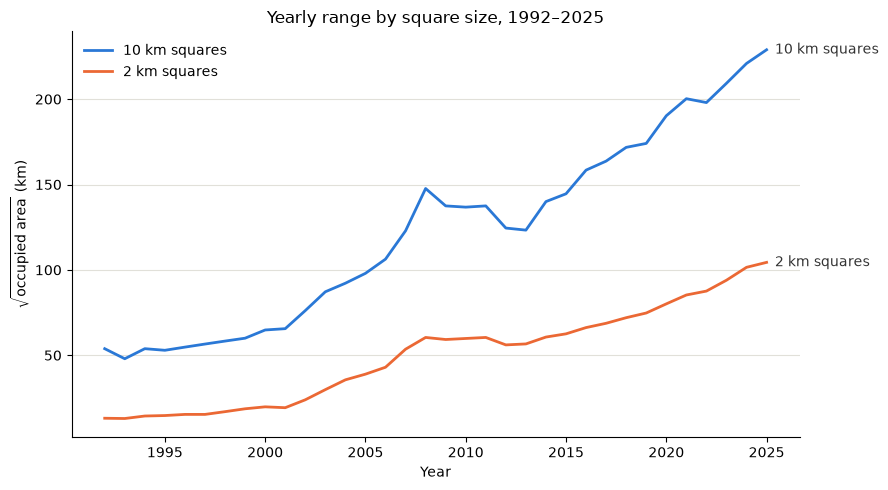

In [24]:
COMPARISON_START = 1992  # from here on, fewer than 10% of NBN records are 10 km only (see 02_spatial-unit)
comparison_years = [y for y in years if y >= COMPARISON_START]
recent = records[records["year"].between(COMPARISON_START, LAST_YEAR)]

# Yearly occupied squares and √(area) at both sizes
compare = pd.DataFrame({
    "squares_10km": recent.groupby("year")["hectad"].nunique().reindex(comparison_years, fill_value=0),
    "squares_2km": recent.groupby("year")["tetrad"].nunique().reindex(comparison_years, fill_value=0),
})
compare.index.name = "year"
compare["sqrt_area_10km"] = np.sqrt(compare["squares_10km"] * 100)  # 10 × 10 km
compare["sqrt_area_2km"] = np.sqrt(compare["squares_2km"] * 4)      # 2 × 2 km

fig, ax = plt.subplots(figsize=(9, 5))
for col, colour, label in [("sqrt_area_10km", YEARLY_COLOUR, "10 km squares"),
                           ("sqrt_area_2km", CUMULATIVE_COLOUR, "2 km squares")]:
    ax.plot(compare.index, compare[col], color=colour, linewidth=2, label=label)
    ax.annotate(label, (compare.index[-1], compare[col].iloc[-1]),
                xytext=(6, 0), textcoords="offset points", va="center", color=TEXT)

ax.set_xlabel("Year")
ax.set_ylabel(r"$\sqrt{\text{occupied area}}$ (km)")
ax.set_title(f"Yearly range by square size, {COMPARISON_START}–{LAST_YEAR}")
ax.legend(frameon=False, loc="upper left")
ax.grid(axis="y", color=GRID, linewidth=0.8)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()

fig.savefig(FIGURES / "sqrt_area_10km_vs_2km.png", dpi=200)

# Ratio of 2 km to 10 km area: if roughly constant, both sizes tell the same story
(compare["sqrt_area_2km"] / compare["sqrt_area_10km"]).round(2).rename("ratio_2km_to_10km")

In [25]:
nbn_recent = recent[recent["source"] == "NBN"]
ratio_nbn = (np.sqrt(nbn_recent.groupby("year")["tetrad"].nunique() * 4)
             / np.sqrt(nbn_recent.groupby("year")["hectad"].nunique() * 100))
pd.DataFrame({"all": compare["sqrt_area_2km"] / compare["sqrt_area_10km"],
              "NBN only": ratio_nbn}).round(2)


,all,NBN only
year,,
1992,0.24,0.23
1993,0.27,0.26
1994,0.27,0.21
1995,0.28,0.24
1996,0.28,0.25
1997,0.27,0.27
1998,0.29,0.27
1999,0.31,0.29
2000,0.31,0.29


In [27]:
per_square = recent.groupby(["year", "hectad", "source"]).size().rename("n").reset_index()
sparse = per_square[per_square["n"] <= 2]
sparse.groupby(["year", "source"]).size().unstack(fill_value=0)

source,GBIF,NBN
year,,
1992,15,12
1993,10,9
1994,11,19
1995,12,12
1996,14,16
1997,13,17
1998,12,15
1999,12,18
2000,16,16


In [ ]:
jump_years = records[records["year"].isin([1980, 1981, 1987, 1988, 2007, 2008, 2012])]
(jump_years.groupby(["year", "dataset"])["hectad"].nunique()
           .sort_values(ascending=False).groupby(level=0).head(3))

year  dataset                                                                              
2008  Birds (BTO+partners)                                                                     206
2012  Birds (BTO+partners)                                                                     135
2007  Birds (BTO+partners)                                                                     132
1981  BTO First Atlas of Wintering Birds in Britain and Ireland: 1981/82-1983/84                70
2012  EOD – eBird Observation Dataset                                                           67
1988  BTO Second Atlas of Breeding Birds in Britain and Ireland: 1988-1991                      63
2007  EOD – eBird Observation Dataset                                                           42
2008  EOD – eBird Observation Dataset                                                           42
2012  Birds (BTO/JNCC/RSPB partnership)                                                         38
2008  Birds (BTO/